# Репертуары TCRβ у наивных CD4⁺ и CD8⁺ T-клеток

Как отличаются длина CDR3, использование генов и разнообразие TRB между группами доноров? Повторяем основные расчёты семинарского ноутбука отдельно для nCD4 и nCD8. Единица сравнения — образец донора. Три группы пуповинной крови (preterm, term, late) соответствуют гестационным срокам. У детей, взрослых и старших взрослых исследовали периферическую кровь.

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from repseq import stats, beta
from repseq.clone_filter import Filter

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'environment.yml').is_file())
data = root / 'data' / 'ucb_figshare'
out = root / 'outputs' / 'repseq'
out.mkdir(parents=True, exist_ok=True)
groups = ['preterm', 'term', 'late', 'children', 'adults', 'older_adults']
subsets = ['nCD4', 'nCD8']
colors = dict(zip(groups, sns.color_palette('colorblind', len(groups))))
meta = pd.read_csv(data / 'ucb_figshare_TRB_metadata.csv').query("subset in @subsets and chain == 'TRB'").copy()
meta['experimental_group'] = pd.Categorical(meta.experimental_group, groups, ordered=True)
meta = meta.sort_values(['subset', 'experimental_group', 'sample_id']).set_index('sample_id')
assert meta.index.is_unique and not meta.duplicated(['subset', 'donor_id']).any()
assert all((data / f).is_file() for f in meta.filename)
display(pd.crosstab(meta.experimental_group, meta.subset))
display(pd.crosstab(meta.experimental_group, meta.sorting_subtype))

subset,nCD4,nCD8
experimental_group,,
preterm,3,3
term,6,6
late,4,4
children,4,4
adults,9,4
older_adults,4,6


sorting_subtype,mnCD4,nCD4,nCD8
experimental_group,,,
preterm,0,3,3
term,2,4,6
late,0,4,4
children,4,0,4
adults,9,0,4
older_adults,4,0,6


## Глубина и фильтрация

Сверяем число функциональных строк и сумму их счётчиков с метаданными. В этих таблицах MiGEC → MiXCR поле `cloneCount` отражает молекулярные наблюдения. Одна молекула РНК и одна клетка — разные единицы. Параметр `by_umi=True` использует доступный счётчик. Функциональность определяется по CDR3 по правилам семинара.

In [2]:
samples = meta.reset_index().assign(filename=lambda d: d.filename.map(lambda name: str(data / name)))
qc = stats.calc_clonoset_stats(samples[['sample_id', 'filename', 'chain']], cpu=1, verbose=False).set_index('sample_id')
meta = meta.join(qc[['clones_func', 'reads_func']])
assert (meta.clones_func == meta.clonotypes_functional).all() and (meta.reads_func == meta.UMI_functional).all()
depth = int(meta.reads_func.min() // 1000 * 1000)
depths = [depth // 2, depth]
display(meta.groupby('subset')[['clones_func', 'reads_func']].agg(['min', 'median', 'max']))
print('Глубины проверки и основного сравнения:', depths)

clones_func                  reads_func                 
               min   median     max        min   median     max
subset                                                         
nCD4          4508  35065.0  119344       5912  48871.0  254528
nCD8          4931  34463.0  103879       6368  50019.0  193529

Глубины проверки и основного сравнения: [2500, 5000]


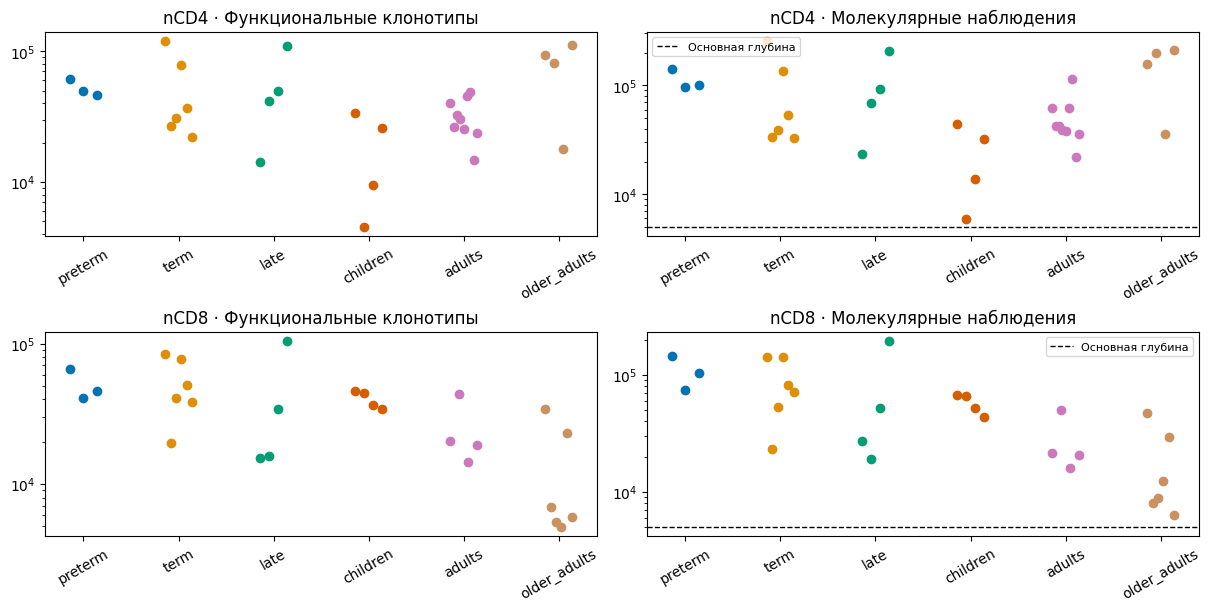

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout='constrained')
for subset, axis_row in zip(subsets, axes):
    for metric, ax, title in zip(['clones_func','reads_func'], axis_row, ['Функциональные клонотипы','Молекулярные наблюдения']):
        for pos, (group, block) in enumerate(meta.query('subset == @subset').groupby('experimental_group', observed=True)):
            values = block[metric].to_numpy()
            ax.scatter(pos + np.linspace(-.14,.14,len(values)), values, color=colors[group])
        if metric == 'reads_func':
            ax.axhline(depth, color='black', ls='--', lw=1, label='Основная глубина')
            ax.legend(fontsize=8)
        ax.set(yscale='log', title=f'{subset} · {title}', xticks=range(len(groups)), xticklabels=groups)
        ax.tick_params(axis='x', labelrotation=30)
plt.show()

Основная глубина — наибольшее целое число тысяч, доступное каждому образцу обеих популяций. Половина этой глубины служит проверкой чувствительности на тех же донорах. Для α-разнообразия и конвергенции усредняем три выборки без возвращения внутри образца. Для F2 берём первую выборку на основной глубине. Для длины, V/J и rarefaction используем все функциональные наблюдения каждого образца.

In [4]:
columns = ['cloneCount', 'cloneFraction', 'aaSeqCDR3', 'nSeqCDR3', 'allVHitsWithScore', 'allJHitsWithScore']
functional = Filter(functionality='f', by_umi=True)
rng = np.random.default_rng(100)
alpha_rows, profiles, rare_rows = [], [], []
frequencies = {}

for sample_id, row in meta.iterrows():
    raw = pd.read_csv(data / row.filename, sep='\t', usecols=columns, keep_default_na=False)
    clones = functional.apply(raw)
    counts = clones['count'].to_numpy(dtype=int)
    assert counts.sum() == row.reads_func and len(clones) == row.clones_func
    for feature in ['CDR3aa', 'v', 'j']:
        labels = clones.cdr3aa.str.len() if feature == 'CDR3aa' else clones[feature]
        weighted = clones.groupby(labels).freq.sum()
        profiles.extend((sample_id, feature, label, value) for label, value in weighted.items())
    curve = stats.calculate_rarefaction_points_cl(clones, rarefaction_iterations=3, rarefaction_seed=100)
    rare_rows.extend((sample_id, size, richness) for size, richness in curve.items())
    for size in depths:
        for run in range(3):
            # Многомерное гипергеометрическое распределение моделирует отбор молекул без возвращения.
            drawn = rng.multivariate_hypergeometric(counts, size, method='marginals')
            selected = clones.loc[drawn > 0].copy()
            selected['count'] = drawn[drawn > 0]
            selected['freq'] = selected['count'] / size
            metrics = stats.calculate_diversity_stats_cl(selected)
            metrics.update(stats.calculate_convergence_cl(selected))
            alpha_rows.append(dict(sample_id=sample_id, depth=size, run=run, **metrics))
            if size == depth and run == 0:
                frequencies[sample_id] = selected.groupby(['cdr3aa', 'v']).freq.sum()
alpha = pd.DataFrame(alpha_rows).groupby(['sample_id', 'depth']).mean().drop(columns='run').reset_index()
alpha = alpha.merge(meta[['subset', 'experimental_group']], on='sample_id', validate='many_to_one')
profile = pd.DataFrame(profiles, columns=['sample_id', 'feature', 'label', 'frequency'])
rare = pd.DataFrame(rare_rows, columns=['sample_id', 'depth', 'richness']).merge(meta[['subset', 'experimental_group']], on='sample_id')
alpha.to_csv(out / 'alpha_convergence.csv', index=False)
rare.to_csv(out / 'rarefaction.csv', index=False)
main = alpha.query('depth == @depth')
display(main.groupby(['subset', 'experimental_group'], observed=True)[['diversity', 'shannon_wiener', 'clonality', 'convergence']].median().round(4))

diversity  shannon_wiener  clonality  convergence
subset experimental_group                                                   
nCD4   preterm             4752.6667          8.4449     0.0026       1.0529
       term                4818.6667          8.4659     0.0017       1.0061
       late                4783.8333          8.4564     0.0020       1.0055
       children            4552.1667          8.3861     0.0043       1.0023
       adults              4719.3333          8.4380     0.0025       1.0020
       older_adults        4855.6667          8.4764     0.0013       1.0025
nCD8   preterm             4694.0000          8.4280     0.0031       1.0769
       term                4826.6667          8.4681     0.0016       1.0135
       late                4753.6667          8.4475     0.0023       1.0090
       children            4814.3333          8.4642     0.0018       1.0038
       adults              4895.0000          8.4857     0.0012       1.0033
       older_adults        4535.5000          8.3106     0.0129       1.0039

## CDR3 и использование V/J

Для каждого донора рассчитываем долю молекул с данной длиной CDR3 или назначенным геном. На графиках показаны арифметические средние долей по донорам группы. Отсутствующий в образце ген получает нулевую долю. Для читаемости на тепловых картах показаны восемь наиболее частых генов каждого типа.

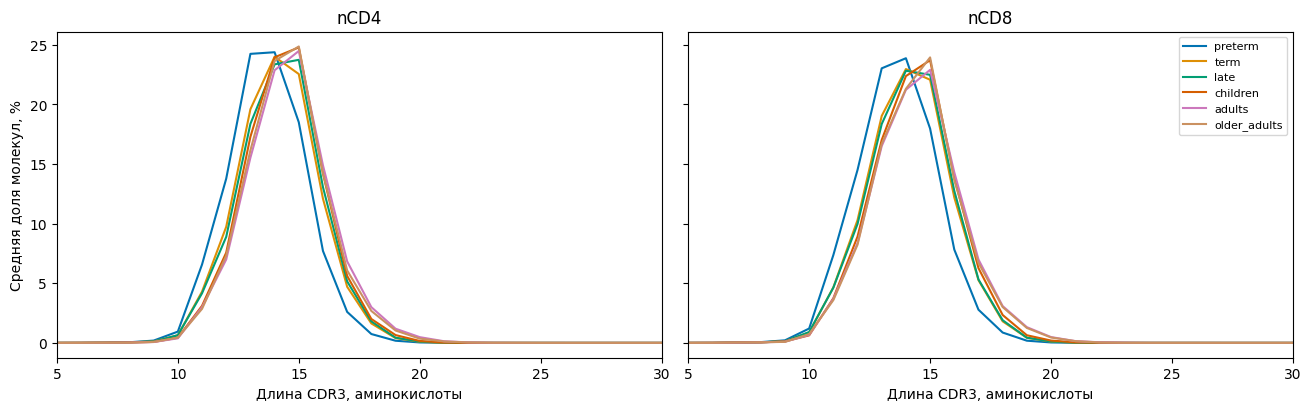

subset,nCD4,nCD8
experimental_group,,
preterm,13.60,13.59
term,14.16,14.16
late,14.24,14.18
children,14.36,14.36
adults,14.56,14.44
older_adults,14.49,14.45


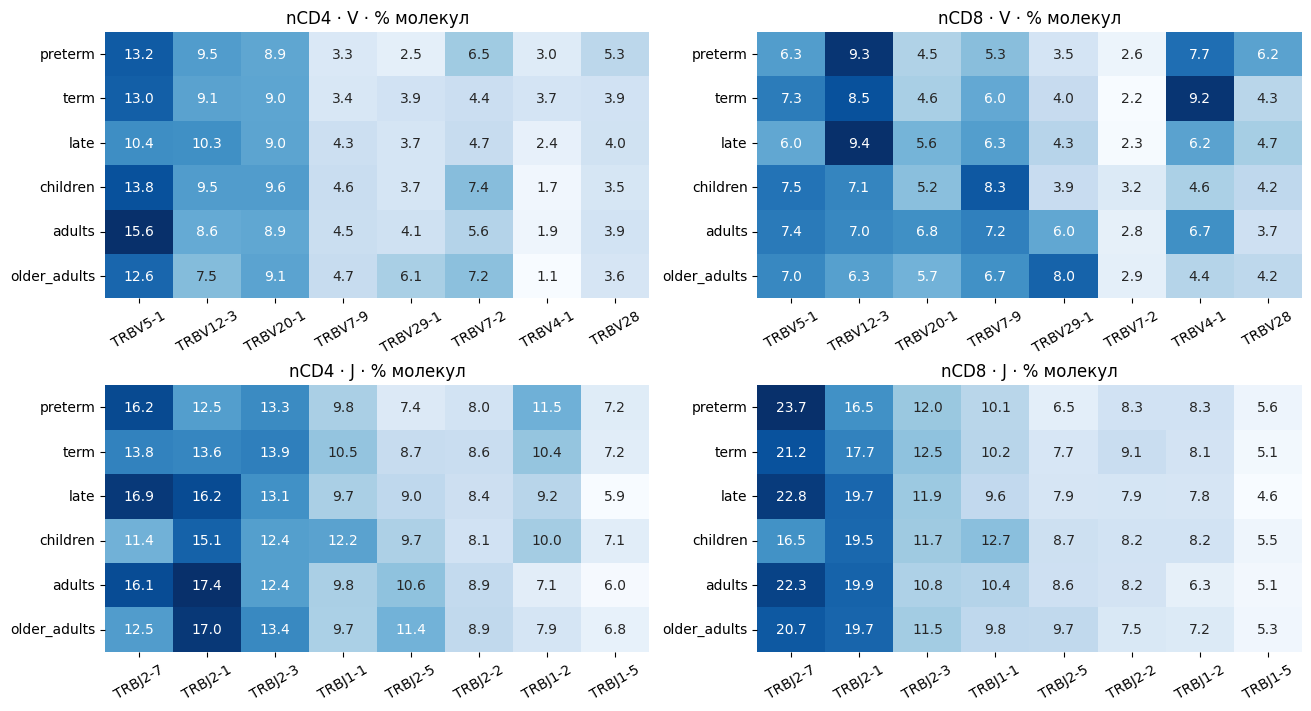

In [5]:
def sample_profile(feature):
    return profile.query('feature == @feature').pivot(index='sample_id', columns='label', values='frequency').fillna(0)

lengths = sample_profile('CDR3aa')
lengths.columns = lengths.columns.astype(int)
assert np.allclose(lengths.sum(axis=1), 1)
mean_length = lengths.mul(lengths.columns, axis=1).sum(axis=1).rename('mean_cdr3_aa')
meta = meta.join(mean_length)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, layout='constrained')
for subset, ax in zip(subsets, axes):
    samples_here = meta.query('subset == @subset')
    for group, ids in samples_here.groupby('experimental_group', observed=True).groups.items():
        ax.plot(lengths.columns, 100*lengths.loc[ids].mean(), label=group, color=colors[group])
    ax.set(title=subset, xlabel='Длина CDR3, аминокислоты', xlim=(5, 30))
axes[0].set_ylabel('Средняя доля молекул, %')
axes[1].legend(fontsize=8)
plt.show()
display(meta.groupby(['subset', 'experimental_group'], observed=True).mean_cdr3_aa.median().round(2).unstack(0))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout='constrained')
for feature, axis_row in zip(['v', 'j'], axes):
    usage = sample_profile(feature)
    top = usage.mean().nlargest(8).index
    for subset, ax in zip(subsets, axis_row):
        ids = meta.query('subset == @subset').index
        panel = usage.loc[ids, top].groupby(meta.experimental_group, observed=True).mean()
        sns.heatmap(100*panel, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax)
        ax.set(title=f'{subset} · {feature.upper()} · % молекул', ylabel='', xlabel='')
        ax.tick_params(axis='x', labelrotation=30)
plt.show()
profile.to_csv(out / 'length_v_j.csv', index=False)
meta[['subset','experimental_group','clones_func','reads_func','mean_cdr3_aa']].to_csv(out / 'sample_qc.csv')

## Свойства CDR3

Повторяем расчёт семинара на полных функциональных клоносетах. Библиотека усредняет свойства аминокислот с весом по частоте клонотипа. Сравниваем длину вставок в нуклеотидах, долю молекул без вставок и заряд пяти центральных остатков CDR3.

In [6]:
# Используем таблицу аминокислот из установленного пакета repseq 0.1.3.
stats.AA_PROPS_PATH = Path(stats.__file__).parent / 'resourses' / 'aa_property_table.txt'
properties = stats.calc_cdr3_properties(samples[['sample_id', 'filename', 'chain']],
                                       cl_filter=functional, cpu=1, verbose=False)
properties = properties.set_index('sample_id').join(meta[['subset','experimental_group']])
properties.to_csv(out / 'cdr3_properties.csv')
prop_cols = ['mean_insert_size','zero_insert_freq','cdr3_5_charge']
display(properties.groupby(['subset','experimental_group'], observed=True)[prop_cols].median().round(3))

mean_insert_size  zero_insert_freq  cdr3_5_charge
subset experimental_group                                                   
nCD4   preterm                        3.498             0.236          0.058
       term                           6.178             0.053          0.125
       late                           6.254             0.051          0.118
       children                       7.132             0.022          0.108
       adults                         7.480             0.020          0.114
       older_adults                   7.296             0.021          0.082
nCD8   preterm                        3.237             0.268         -0.091
       term                           5.833             0.074         -0.070
       late                           6.177             0.058         -0.043
       children                       7.031             0.024         -0.073
       adults                         7.366             0.023         -0.091
       older_adults                   7.116             0.025         -0.015

## α-разнообразие, конвергенция и зависимость от глубины

Богатство — число наблюдаемых клонотипов, индекс Шеннона учитывает их частоты. Конвергенция — отношение числа уникальных CDR3nt к числу уникальных CDR3aa. Значение выше единицы означает, что часть разных нуклеотидных последовательностей кодирует одинаковый пептид.

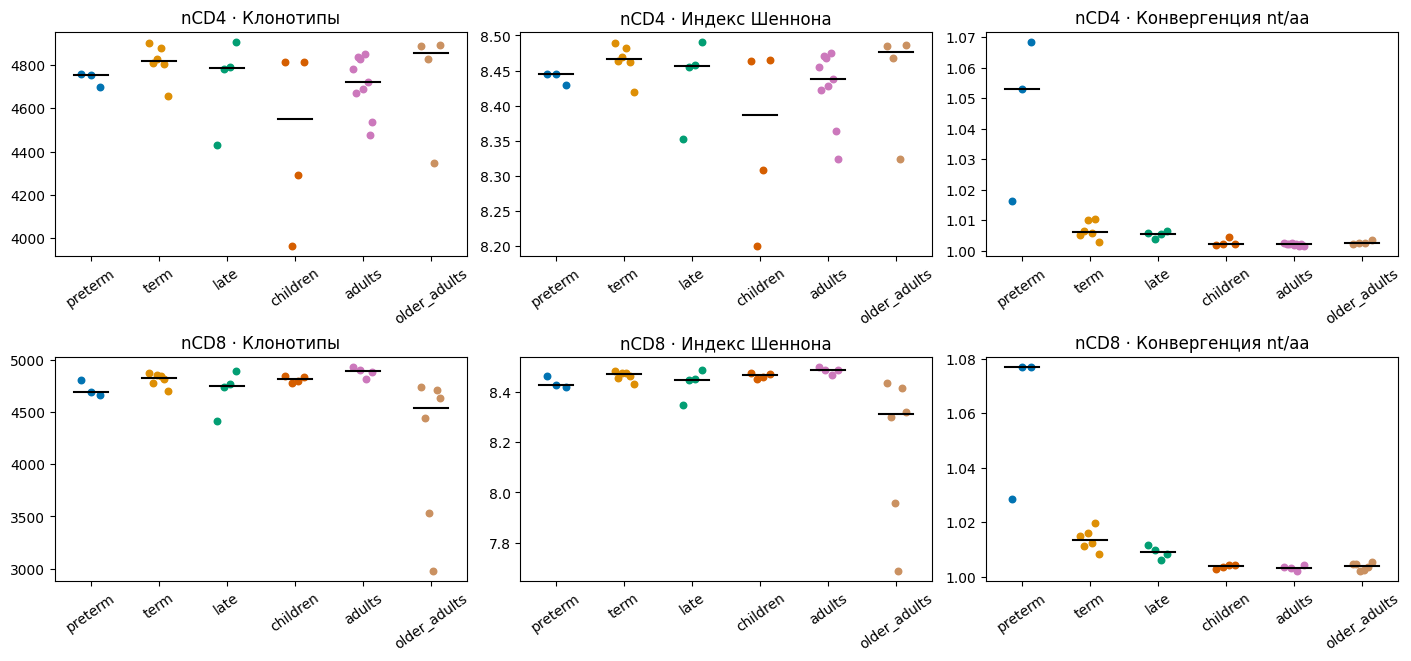

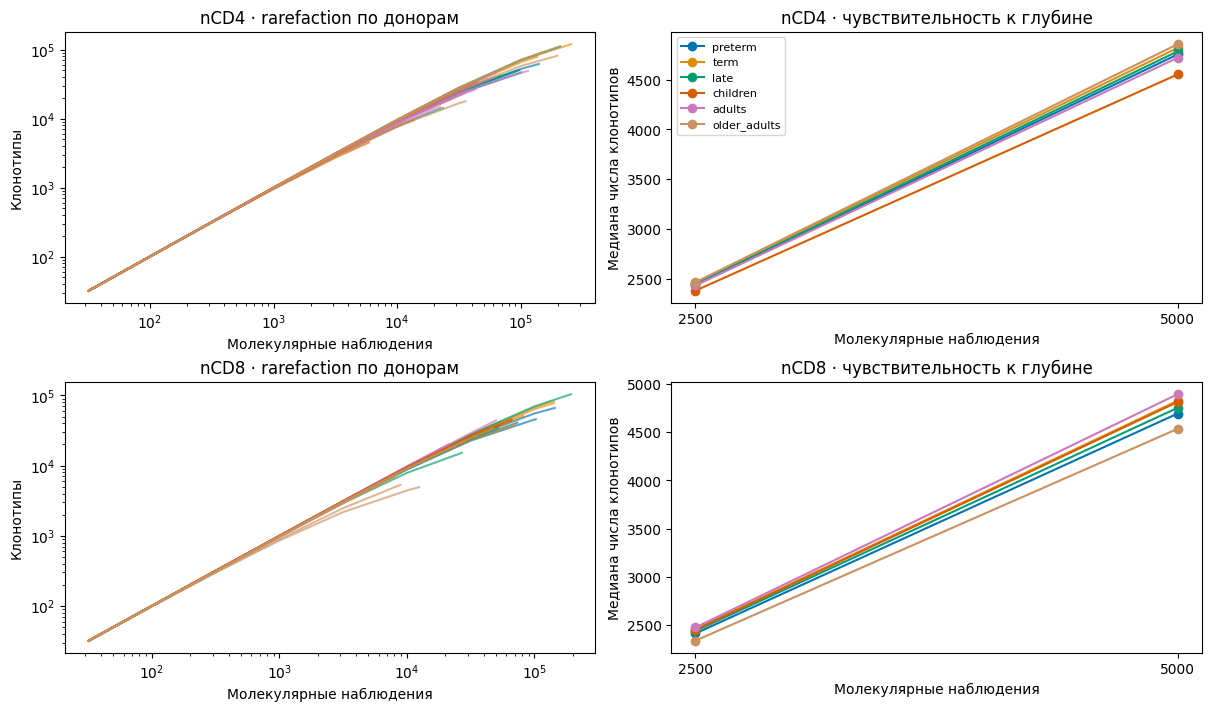

depth                        2500    5000
subset experimental_group                
nCD4   preterm             2436.7  4752.7
       term                2458.7  4818.7
       late                2443.3  4783.8
       children            2378.8  4552.2
       adults              2431.3  4719.3
       older_adults        2463.5  4855.7
nCD8   preterm             2411.3  4694.0
       term                2457.8  4826.7
       late                2437.8  4753.7
       children            2449.3  4814.3
       adults              2474.0  4895.0
       older_adults        2336.3  4535.5

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), layout='constrained')
for subset, axis_row in zip(subsets, axes):
    for ax, metric, title in zip(axis_row, ['diversity','shannon_wiener','convergence'], ['Клонотипы','Индекс Шеннона','Конвергенция nt/aa']):
        for pos, (group, block) in enumerate(main.query('subset == @subset').groupby('experimental_group', observed=True)):
            y = block[metric].to_numpy()
            ax.scatter(pos + np.linspace(-.14,.14,len(y)), y, color=colors[group], s=22)
            ax.plot([pos-.25,pos+.25],[np.median(y)]*2, color='black')
        ax.set(title=f'{subset} · {title}', xticks=range(len(groups)), xticklabels=groups)
        ax.tick_params(axis='x', labelrotation=35)
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout='constrained')
for subset, (ax, sens) in zip(subsets, axes):
    for label, line in rare.query('subset == @subset').groupby('sample_id'):
        ax.plot(line.depth, line.richness, color=colors[line.experimental_group.iloc[0]], alpha=.65)
    ax.set(xscale='log', yscale='log', xlabel='Молекулярные наблюдения', ylabel='Клонотипы', title=f'{subset} · rarefaction по донорам')
    for group, block in alpha.query('subset == @subset').groupby('experimental_group', observed=True):
        line = block.groupby('depth').diversity.median()
        sens.plot(line.index, line, 'o-', color=colors[group], label=group)
    sens.set(xticks=depths, xlabel='Молекулярные наблюдения', ylabel='Медиана числа клонотипов', title=f'{subset} · чувствительность к глубине')
axes[0,1].legend(fontsize=8)
plt.show()
display(alpha.groupby(['subset','experimental_group','depth'], observed=True).diversity.median().unstack().round(1))

## Сходство репертуаров и MDS

Для каждой популяции объединяем частоты по ключу (CDR3aa, V). F2 равен сумме квадратных корней из произведений частот общих ключей. Скалярное произведение векторов √частот вычисляет ту же метрику без большой промежуточной таблицы всех пар. Диагональ равна единице и скрыта на графике. Для MDS используем функцию семинара `beta.mds` с преобразованием расстояний −log₁₀(F2).

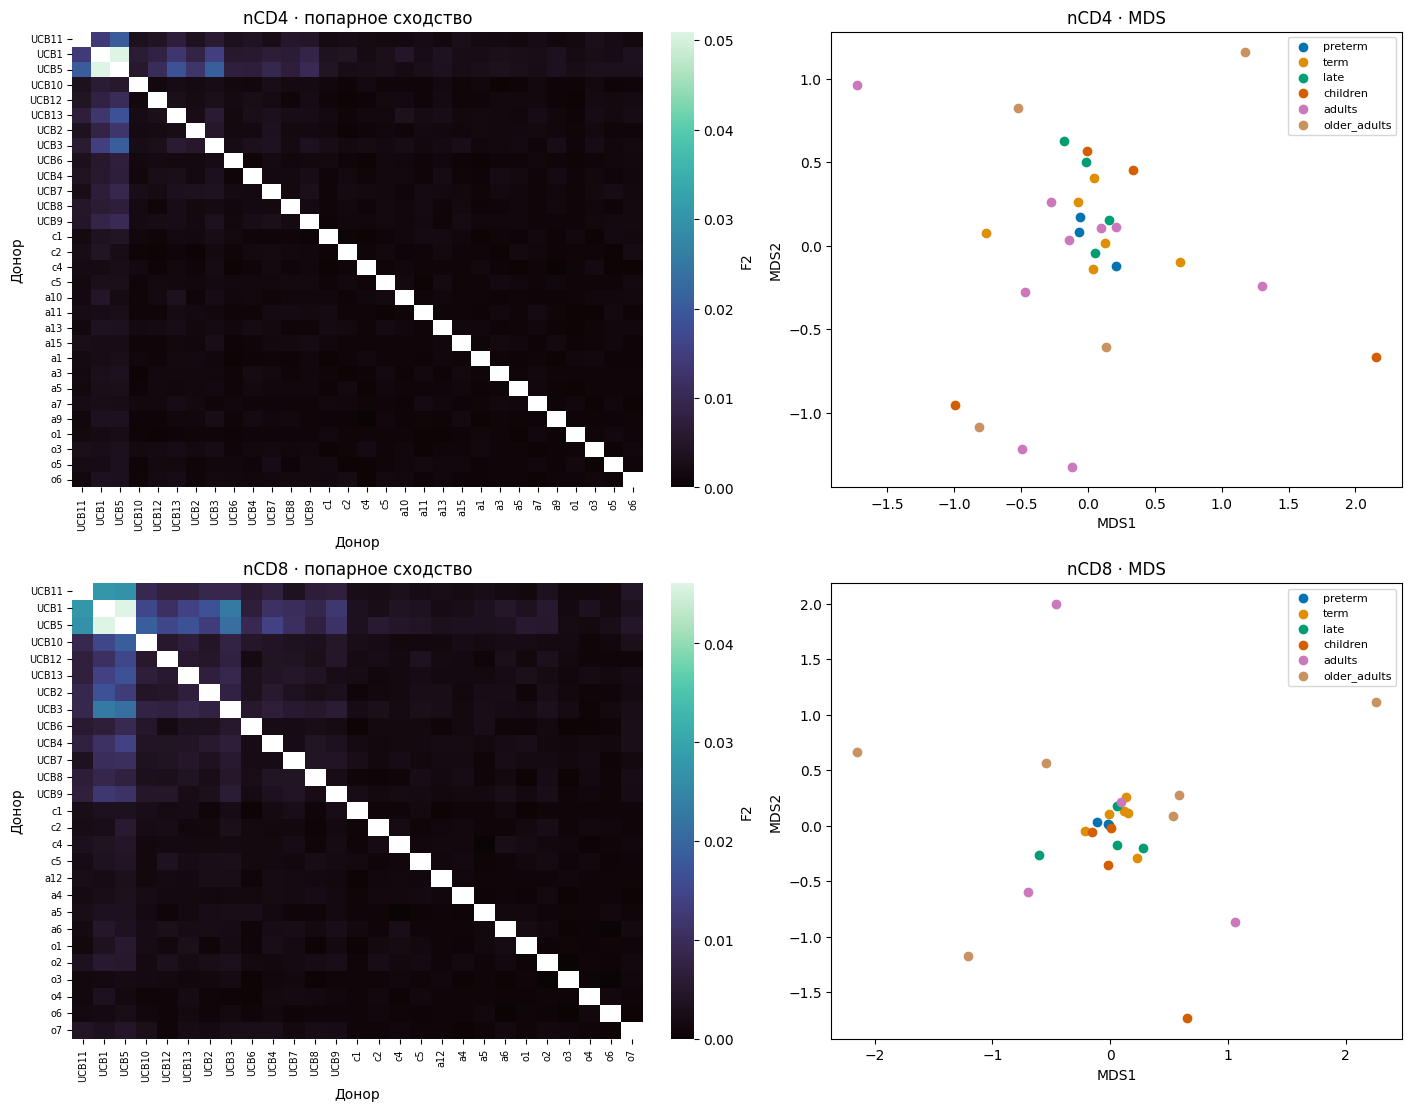

size   median      min      max
subset пара тканей                                 
nCD4   PBMC / PBMC   136  0.00076  0.00000  0.00208
       PBMC / UCB    221  0.00128  0.00020  0.00488
       UCB / UCB      78  0.00321  0.00080  0.05097
nCD8   PBMC / PBMC    91  0.00080  0.00000  0.00245
       PBMC / UCB    182  0.00177  0.00020  0.00548
       UCB / UCB      78  0.00566  0.00177  0.04611

In [8]:
from scipy.sparse import csr_matrix

pair_rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 11), layout='constrained')
for subset, (heat, scatter) in zip(subsets, axes):
    ids = meta.query('subset == @subset').index
    long = pd.concat({i: frequencies[i] for i in ids}, names=['sample_id']).rename('p').reset_index()
    keys = pd.MultiIndex.from_frame(long[['cdr3aa','v']])
    columns, distinct_keys = pd.factorize(keys)
    x = csr_matrix((np.sqrt(long.p), (ids.get_indexer(long.sample_id), columns)), shape=(len(ids), len(distinct_keys)))
    matrix = pd.DataFrame((x @ x.T).toarray(), index=ids, columns=ids)
    assert np.allclose(np.diag(matrix), 1) and np.allclose(matrix, matrix.T)
    matrix.to_csv(out / f'{subset}_f2.csv')
    short = [i.split('_')[0] for i in ids]
    sns.heatmap(matrix, mask=np.eye(len(ids),dtype=bool), cmap='mako', ax=heat, xticklabels=short, yticklabels=short, cbar_kws={'label':'F2'})
    heat.set(title=f'{subset} · попарное сходство', xlabel='Донор', ylabel='Донор')
    heat.tick_params(labelsize=7)
    coords = beta.mds(matrix).set_index('sample_id').join(meta[['experimental_group']])
    coords.to_csv(out / f'{subset}_mds.csv')
    for group, block in coords.groupby('experimental_group', observed=True):
        scatter.scatter(block.MDS1, block.MDS2, label=group, color=colors[group])
    scatter.set(title=f'{subset} · MDS', xlabel='MDS1', ylabel='MDS2')
    scatter.legend(fontsize=8)
    for a,b in combinations(ids, 2):
        source_a = meta.loc[a,'tissue']
        source_b = meta.loc[b,'tissue']
        pair_rows.append((subset, ' / '.join(sorted([source_a,source_b])), matrix.loc[a,b]))
plt.show()
pairs = pd.DataFrame(pair_rows, columns=['subset','пара тканей','F2'])
display(pairs.groupby(['subset','пара тканей']).F2.agg(['size','median','min','max']).round(5))

## Выводы

**Длина CDR3 и конвергенция.** У недоношенных доноров медиана средневзвешенной длины CDR3 составила 13,60 аминокислоты в nCD4 и 13,59 в nCD8. У взрослых значения выше в обеих популяциях (14,56 и 14,44). Одновременно в группе preterm конвергенция выше, особенно у nCD8 (1,077 против 1,003 у взрослых). Медиана средней длины вставок у preterm также меньше, чем у взрослых (3,50 против 7,48 нуклеотида для nCD4 и 3,24 против 7,37 для nCD8). В этой выборке у недоношенных чаще встречались разные нуклеотидные варианты одной аминокислотной CDR3.

**V/J-профиль.** У nCD4 во всех шести группах наибольшая средняя доля принадлежит TRBV5-1. У nCD8 лидер зависит от группы, например TRBV12-3 у preterm и TRBV29-1 у older_adults. Среди J-генов nCD8 TRBJ2-7 занимает первое место в пяти группах из шести. Поэтому различия между популяциями видны и в выборе сегментов, хотя набор часто используемых генов пересекается.

**Разнообразие и глубина.** При 5 000 наблюдений медиана богатства nCD8 составила 4 895 клонотипов у взрослых и 4 536 у старших взрослых. Индекс Шеннона также ниже у старших взрослых (8,31 против 8,49), что согласуется с большим вкладом частых клонотипов. Для nCD4 направление другое (4 719 и 4 856 клонотипов соответственно). При глубине 2 500 сохраняются оба направления. Абсолютное богатство падает почти вдвое, а кривые разрежения продолжают расти вплоть до измеренной глубины. Полученное богатство характеризует объём выборки.

**Сходство доноров.** Общие CDR3aa с совпадающим V-геном встречаются чаще или занимают большую суммарную долю в парах образцов пуповинной крови. Медиана F2 в парах UCB/UCB равна 0,00321 для nCD4 и 0,00566 для nCD8. Для пар PBMC/PBMC значения равны 0,00076 и 0,00080. Даже в UCB перекрытие невелико. На MDS виден разброс доноров, и возрастные группы частично перекрываются.

**Ограничения.** В группе preterm всего три образца каждой популяции. Источник крови меняется вместе с возрастной группой. В периферической крови все образцы nCD4 имеют подтип сортировки mnCD4, тогда как в пуповинной крови встречаются оба варианта сортировки. Возраст, источник материала и гейтинг могут вносить вклад в различия. Сравнения описательные, а пары F2 с общим донором зависимы.